## **Manual Data Profiling**

Data profiling is the first contact with a dataset: *how big is it, what does each attribute look like, how are the attributes related and what looks suspicious?*
In this notebook the profile is built **manually**, command by command, so every number can be understood, reproduced and questioned.

**Notebooks of this series:** 1. Manual Data Profiling · 2. Automatic Data Profiling · 3. Checking Issues in Dataframes · 4. Graphics & Illustrations · 5. EDA for Time Series

### **00. Import Libs and the DataSet**

In [3]:
#Import Specific Libs
from scipy import stats
from google.colab import files;
from collections import Counter;
from IPython.display import IFrame, display, HTML;

In [4]:
#Import the Others Libs
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import plotly.express as px
import seaborn as sns
import pandas as pd
import numpy as np
import re

In [ ]:
#Import Statistical and Machine Learning Libs
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.feature_selection import mutual_info_classif

In [6]:
#Ignore Error Message
import warnings
warnings.simplefilter(action='ignore', category=FutureWarning)

In [7]:
#Import Dataframe from Github
df = pd.read_csv('https://raw.githubusercontent.com/jrafa1607/DataScience-ML-AI/main/-%20Datasets/credit_data.csv')

### **01. Manual Data Profiling**

In [8]:
#Database Visualization with Print
print(df)

      i#clientid        income        age         loan  c#default
0              1  66155.925095  59.017015  8106.532131          0
1              2  34415.153966  48.117153  6564.745018          0
2              3  57317.170063  63.108049  8020.953296          0
3              4  42709.534201  45.751972  6103.642260          0
4              5  66952.688845  18.584336  8770.099235          1
...          ...           ...        ...          ...        ...
1995        1996  59221.044874  48.518179  1926.729397          0
1996        1997  69516.127573  23.162104  3503.176156          0
1997        1998  44311.449262  28.017167  5522.786693          1
1998        1999  43756.056605  63.971796  1622.722598          0
1999        2000  69436.579552  56.152617  7378.833599          0

[2000 rows x 5 columns]


In [9]:
#Database Visualization with Interactive Table
df.head(3)

,i#clientid,income,age,loan,c#default
0,1,66155.925095,59.017015,8106.532131,0
1,2,34415.153966,48.117153,6564.745018,0
2,3,57317.170063,63.108049,8020.953296,0


In [10]:
#Attributes View
print(df.columns)

Index(['i#clientid', 'income', 'age', 'loan', 'c#default'], dtype='object')


In [11]:
#Define New Attributes Names
df.columns = ['id', 'income', 'age', 'loan', 'result']
df.head(3)

,id,income,age,loan,result
0,1,66155.925095,59.017015,8106.532131,0
1,2,34415.153966,48.117153,6564.745018,0
2,3,57317.170063,63.108049,8020.953296,0


In [12]:
#Change the Name of the Specific Attribute
df = df.rename(columns={df.columns[0]: "Index"})
df.head(3)

,Index,income,age,loan,result
0,1,66155.925095,59.017015,8106.532131,0
1,2,34415.153966,48.117153,6564.745018,0
2,3,57317.170063,63.108049,8020.953296,0


In [13]:
#Total of Rows and Attributes
df.shape

(2000, 5)

In [14]:
#Show the Dataframe Info
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 5 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Index   2000 non-null   int64  
 1   income  2000 non-null   float64
 2   age     1997 non-null   float64
 3   loan    2000 non-null   float64
 4   result  2000 non-null   int64  
dtypes: float64(3), int64(2)
memory usage: 78.3 KB


In [ ]:
#Data Types and Memory Usage
memory = df.memory_usage(deep=True, index=False)
print(f'Total memory: {memory.sum() / 1024:.1f} KB')
pd.DataFrame({'dtype': df.dtypes, 'memory_KB': (memory / 1024).round(2)})

In [ ]:
#Beginning, End and Random Sample of the Data
# A random sample is more representative than head() when the file is sorted ( by date, by id, by class ... )
pd.concat([df.head(3), df.sample(3, random_state=42), df.tail(3)], keys=['head', 'sample', 'tail'])

In [15]:
#Search Uniques Values (Values, Count, Percentage and Most Frequently)
print(df.result.value_counts(), "\n")
print(df.result.value_counts(normalize=True) * 100, "\n")

result
0    1717
1     283
Name: count, dtype: int64 

result
0    85.85
1    14.15
Name: proportion, dtype: float64 



In [16]:
#Show the Most Frequent Value in the Attribute
print(df['result'].mode())

0    0
Name: result, dtype: int64


In [17]:
#Describe the DataFrame
df.describe()

,Index,income,age,loan,result
count,2000.000000,2000.000000,1997.000000,2000.000000,2000.000000
mean,1000.500000,45331.600018,40.807559,4444.369695,0.141500
std,577.494589,14326.327119,13.624469,3045.410024,0.348624
min,1.000000,20014.489470,-52.423280,1.377630,0.000000
25%,500.750000,32796.459717,28.990415,1939.708847,0.000000
50%,1000.500000,45789.117313,41.317159,3974.719419,0.000000
75%,1500.250000,57791.281668,52.587040,6432.410625,0.000000
max,2000.000000,69995.685578,63.971796,13766.051239,1.000000


In [ ]:
#Describe with Percentiles and Missing Count
description = df.describe(percentiles=[0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99]).T
description['missing'] = df.isnull().sum()
description.round(2)

In [18]:
#Correlation Matrix Between the Attributes
df.corr()

,Index,income,age,loan,result
Index,1.000000,0.039280,-0.014704,0.018931,-0.020145
income,0.039280,1.000000,-0.033687,0.441117,0.002284
age,-0.014704,-0.033687,1.000000,0.002309,-0.429759
loan,0.018931,0.441117,0.002309,1.000000,0.377160
result,-0.020145,0.002284,-0.429759,0.377160,1.000000


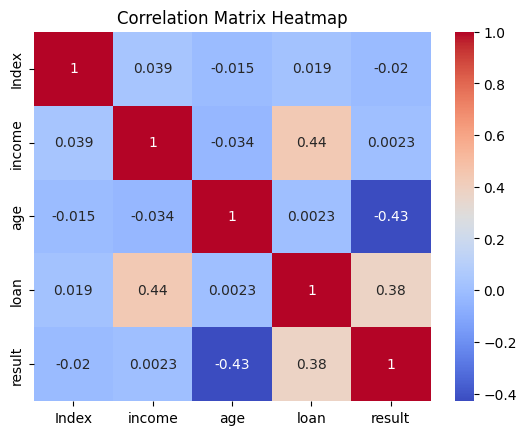

In [19]:
#Correlation Matrix Heatmap
sns.heatmap(df.corr(), annot=True, cmap='coolwarm')
plt.title('Correlation Matrix Heatmap')
plt.show()

In [20]:
#Define the Numerical Attributes and the Target
num_cols = ['income', 'age', 'loan']
target = 'result'

In [21]:
#Unique Values per Attribute ( Cardinality )
cardinality = pd.DataFrame({
    'dtype': df.dtypes,
    'unique_values': df.nunique(),
    'unique_%': (df.nunique() / len(df) * 100).round(2)
})
cardinality

,dtype,unique_values,unique_%
Index,int64,2000,100.00
income,float64,2000,100.00
age,float64,1997,99.85
loan,float64,2000,100.00
result,int64,2,0.10


In [22]:
#Extended Descriptive Statistics ( Median, IQR, CV, Skewness and Kurtosis )
# Skewness: ~0 symmetric | > 1 right-skewed | < -1 left-skewed
# CV (Coefficient of Variation) = std / mean: compares the spread of attributes with different scales
extended = pd.DataFrame({
    'mean': df[num_cols].mean(),
    'median': df[num_cols].median(),
    'std': df[num_cols].std(),
    'iqr': df[num_cols].quantile(0.75) - df[num_cols].quantile(0.25),
    'cv_%': df[num_cols].std() / df[num_cols].mean() * 100,
    'skewness': df[num_cols].skew(),
    'kurtosis': df[num_cols].kurt()
}).round(2)
extended

,mean,median,std,iqr,cv_%,skewness,kurtosis
income,45331.60,45789.12,14326.33,24994.82,31.60,-0.04,-1.20
age,40.81,41.32,13.62,23.60,33.39,-0.31,0.55
loan,4444.37,3974.72,3045.41,4492.70,68.52,0.62,-0.34


In [23]:
#Normality Test ( D'Agostino-Pearson )
# H0: the attribute follows a normal distribution ( p-value < 0.05 rejects H0 )
# With a large sample the test rejects even tiny deviations: always check the Q-Q plot too ( Example 16 )
for col in num_cols:
    stat, p_value = stats.normaltest(df[col].dropna())
    print(f'{col:<8} statistic = {stat:>8.2f} | p-value = {p_value:.2e} | {"Normal" if p_value > 0.05 else "Not Normal"}')

income   statistic =  1630.51 | p-value = 0.00e+00 | Not Normal
age      statistic =    46.78 | p-value = 6.95e-11 | Not Normal
loan     statistic =   124.81 | p-value = 7.89e-28 | Not Normal


**Note:** the *Example 16* ( Q-Q plot ) mentioned in the comment above is in the *Graphics & Illustrations* notebook.

In [24]:
#Spearman Correlation Matrix ( Rank-Based: Robust to Outliers and Captures Monotonic Relations )
df[num_cols + [target]].corr(method='spearman').round(3)

,income,age,loan,result
income,1.000,-0.034,0.402,0.002
age,-0.034,1.000,0.009,-0.440
loan,0.402,0.009,1.000,0.370
result,0.002,-0.440,0.370,1.000


In [25]:
#Correlation of Each Attribute with the Target
corr_target = pd.DataFrame({
    'pearson': df[num_cols].corrwith(df[target]),
    'spearman': df[num_cols].corrwith(df[target], method='spearman')
}).round(3)
corr_target.sort_values('pearson', key=abs, ascending=False)

,pearson,spearman
age,-0.430,-0.440
loan,0.377,0.370
income,0.002,0.002


In [ ]:
#Statistics by Target Class ( Paid = 0 and Default = 1 )
df.groupby(target)[num_cols].agg(['count', 'mean', 'median', 'std']).round(2)

In [ ]:
#Attribute Power to Separate the Classes ( Mann-Whitney U, Cohen's d and AUC )
# Cohen's d: difference between the class means measured in standard deviations ( |d| < 0.2 negligible | 0.5 medium | 0.8 large )
# AUC of one attribute: 0.5 = no separation | 1.0 = perfect separation ( the direction of the relation is ignored )
rows = []
for col in num_cols:
    paid = df.loc[df[target] == 0, col].dropna()
    default = df.loc[df[target] == 1, col].dropna()
    u_stat, p_value = stats.mannwhitneyu(paid, default, alternative='two-sided')
    pooled_std = np.sqrt(((len(paid) - 1) * paid.var() + (len(default) - 1) * default.var()) / (len(paid) + len(default) - 2))
    auc = u_stat / (len(paid) * len(default))
    rows.append({
        'attribute': col,
        'mean_paid': paid.mean(),
        'mean_default': default.mean(),
        'cohens_d': (default.mean() - paid.mean()) / pooled_std,
        'auc': max(auc, 1 - auc),
        'p_value': p_value
    })
separation = pd.DataFrame(rows).set_index('attribute')
separation.sort_values('auc', ascending=False).round({'mean_paid': 2, 'mean_default': 2, 'cohens_d': 3, 'auc': 3})

In [ ]:
#Mutual Information with the Target ( Captures Linear and Non-Linear Relations )
# 0 = the attribute says nothing about the target | the higher the value, the more informative the attribute
complete = df.dropna(subset=num_cols)
mi = mutual_info_classif(complete[num_cols], complete[target], random_state=42)
pd.DataFrame({
    'mutual_information': mi,
    'abs_spearman': complete[num_cols].corrwith(complete[target], method='spearman').abs()
}, index=num_cols).round(3).sort_values('mutual_information', ascending=False)

In [ ]:
#Multicollinearity ( Variance Inflation Factor )
# VIF = 1 / ( 1 - R2 ) of each attribute explained by all the others | ~1 independent | > 5 attention | > 10 severe
features = sm.add_constant(df[num_cols].dropna())
vif = pd.DataFrame({
    'VIF': [variance_inflation_factor(features.values, i) for i in range(1, features.shape[1])]
}, index=num_cols).round(2)
vif

In [ ]:
#Manual Profile of the Whole DataFrame ( One Function, One Table )
def profile_dataframe(data):
    rows = {}
    for col in data.columns:
        s = data[col]
        numeric = pd.api.types.is_numeric_dtype(s)
        rows[col] = {
            'dtype': str(s.dtype),
            'non_null': int(s.notnull().sum()),
            'missing_%': round(s.isnull().mean() * 100, 2),
            'unique': int(s.nunique()),
            'zeros': int((s == 0).sum()) if numeric else np.nan,
            'negatives': int((s < 0).sum()) if numeric else np.nan,
            'min': s.min() if numeric else np.nan,
            'mean': s.mean() if numeric else np.nan,
            'max': s.max() if numeric else np.nan,
            'std': s.std() if numeric else np.nan,
            'skewness': s.skew() if numeric else np.nan
        }
    return pd.DataFrame.from_dict(rows, orient='index')

profile_dataframe(df).round(2)

In [ ]:
#Profiling Summary ( Key Numbers )
missing_cells = int(df.isnull().sum().sum())
class_share = df[target].value_counts(normalize=True)
pd.Series({
    'rows': len(df),
    'attributes': df.shape[1],
    'missing_cells': missing_cells,
    'completeness_%': round((1 - missing_cells / df.size) * 100, 2),
    'duplicated_rows': int(df.duplicated().sum()),
    'negative_values ( numerical attributes )': int((df[num_cols] < 0).sum().sum()),
    'minority_class_%': round(class_share.min() * 100, 2),
    'imbalance_ratio ( majority : minority )': round(class_share.max() / class_share.min(), 1)
}, dtype=object)

### **What the Manual Profile Told Us**

- The dataset has **2000 rows and 5 attributes**; `Index` is only an identifier and must not be used as a feature.
- `age` has **3 missing values and 3 negative values** ( impossible for an age ) and there are no duplicated rows.
- The target `result` is **imbalanced**: 85.85% paid and 14.15% default.
- `income`, `age` and `loan` live on very different scales ( means of about 45 000, 41 and 4 400 ).
- `age` ( -0.43 ) and `loan` ( +0.38 ) are the attributes most correlated with the target; `income` alone is almost uncorrelated ( 0.002 ).

These are **leads, not conclusions**: they are investigated in *Automatic Data Profiling* and *Checking Issues in Dataframes*.